# مشروع الخميس: تحليل بيانات مغادرة عملاء شركة الاتصالات
## Telco Customer Churn – 2026

### مقدمة المشروع

يهدف هذا المشروع إلى تحليل بيانات 7,043 عميلًا لشركة اتصالات، بهدف فهم سلوك العملاء ومعرفة العوامل المرتبطة بتركهم للشركة (Customer Churn).

سنستخدم أدوات تحليل البيانات مثل Pandas وNumPy، ومكتبات التصوير البياني Matplotlib وSeaborn، لتنظيف البيانات واستكشافها وإنشاء خصائص جديدة واختيار أهم المتغيرات.

### المشكلة التي نريد حلها

تواجه شركة الاتصالات مشكلة مغادرة بعض العملاء لخدماتها، وتريد الإدارة معرفة العملاء الأكثر احتمالًا لترك الشركة والعوامل التي قد تؤثر في قرارهم.

### الهدف (Target)

العمود المستهدف هو `Churn`، ويحدد ما إذا كان العميل قد ترك الشركة (Yes) أو استمر معها (No).

### المستفيد من المشروع

إدارة الشركة وفريق خدمة العملاء والتسويق، لمساعدتهم على فهم أسباب مغادرة العملاء ووضع استراتيجيات لتحسين الاحتفاظ بهم.

### مراحل العمل

1. فهم المشكلة والبيانات.
2. فحص البيانات وتنظيفها.
3. التحليل الاستكشافي EDA.
4. هندسة الخصائص Feature Engineering.
5. اختيار الخصائص Feature Selection.
6. إعداد البيانات الجاهزة للنمذجة.
7. بناء Dashboard باستخدام Streamlit.
8. كتابة النتائج والتوصيات.   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("تم تحميل البيانات بنجاح")
print("حجم البيانات:", df.shape)

تم تحميل البيانات بنجاح
حجم البيانات: (7043, 21)


In [6]:
# عرض أول خمسة صفوف من البيانات
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### ملاحظة أولية على البيانات

بعد عرض أول خمسة صفوف، لاحظت أن البيانات تحتوي على معلومات متنوعة عن العملاء، مثل مدة الاشتراك والرسوم الشهرية ونوع العقد والخدمات المستخدمة.

كما يحتوي الجدول على العمود المستهدف Churn الذي يوضح مغادرة العميل للشركة أو استمراره معها.

سنحتاج إلى فحص أنواع الأعمدة والقيم الناقصة قبل اتخاذ قرارات التنظيف.   

In [7]:
# عرض معلومات الأعمدة وأنواع البيانات
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### تحليل أنواع البيانات

تتكون البيانات من 7,043 صفًا و21 عمودًا.

أظهر الفحص وجود 18 عمودًا نصيًا وعمودين من نوع الأعداد الصحيحة وعمود واحد من نوع الأعداد العشرية.

لاحظت أن العمود TotalCharges مخزن كنوع نصي (object)، رغم أنه يمثل إجمالي الرسوم المالية، لذلك يحتاج إلى فحص وتحويل إلى نوع رقمي.

كما أن جميع الأعمدة تظهر 7,043 قيمة غير فارغة حسب الفحص الأول، لكننا سنتحقق من القيم غير الصالحة بعد ذلك.   

### فحص القيم الناقصة والتكرار

في هذه الخطوة سنفحص عدد القيم الناقصة في كل عمود، ونتحقق من وجود صفوف مكررة في البيانات.

يساعدنا ذلك على معرفة جودة البيانات وتحديد ما إذا كنا نحتاج إلى معالجة القيم الناقصة أو حذف التكرارات قبل التحليل.  

In [8]:
# عدد القيم الناقصة في كل عمود
print("Missing Values:")
print(df.isnull().sum())

# إجمالي القيم الناقصة
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# عدد الصفوف المكررة
print("\nDuplicate Rows:")
print(df.duplicated().sum())   

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0


### ملاحظة على جودة البيانات

أظهر الفحص الأولي عدم وجود قيم ناقصة أو صفوف مكررة؛ حيث بلغ إجمالي القيم الناقصة 0، وعدد الصفوف المكررة 0.

لكن لاحظت أن العمود TotalCharges مخزن كنص، لذلك سأتحقق من وجود خلايا فارغة مكتوبة كمسافات قبل البدء بالتنظيف.  

In [9]:
# فحص الخلايا الفارغة المكتوبة كمسافات في TotalCharges
empty_spaces = (df["TotalCharges"].astype(str).str.strip() == "").sum()

print("عدد الخلايا الفارغة في TotalCharges:", empty_spaces)   

عدد الخلايا الفارغة في TotalCharges: 11


### حفظ نسخة قبل التنظيف   

سأحتفظ بنسخة من البيانات الأصلية قبل إجراء أي تعديل، حتى أتمكن من مقارنة البيانات قبل التنظيف وبعده والتحقق من أثر قرارات المعالجة.

In [10]:
# إنشاء نسخة احتياطية من البيانات الأصلية
df_before_cleaning = df.copy()

print("تم حفظ النسخة الأصلية بنجاح")
print("حجم النسخة الأصلية:", df_before_cleaning.shape)

تم حفظ النسخة الأصلية بنجاح
حجم النسخة الأصلية: (7043, 21)


### معالجة القيم الفارغة في TotalCharges

اكتشفت وجود 11 خلية فارغة مكتوبة كمسافات في العمود TotalCharges.

سأحوّل هذه المسافات إلى قيم مفقودة حقيقية، ثم أحوّل العمود إلى نوع رقمي حتى أتمكن من استخدامه في التحليل والحسابات.  

In [11]:
# تحويل المسافات الفارغة إلى قيم مفقودة
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

# تحويل العمود إلى نوع رقمي
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# التحقق من نوع العمود والقيم الناقصة بعد التحويل
print("نوع العمود بعد التحويل:", df["TotalCharges"].dtype)
print("عدد القيم الناقصة:", df["TotalCharges"].isnull().sum())

نوع العمود بعد التحويل: float64
عدد القيم الناقصة: 11


### تعويض القيم الناقصة باستخدام الوسيط

بعد تحويل TotalCharges إلى نوع رقمي، ظهرت 11 قيمة ناقصة.

قررت تعويضها باستخدام الوسيط (Median)، لأنه أقل تأثرًا بالقيم المتطرفة مقارنة بالمتوسط، ويساعد على المحافظة على توزيع البيانات.  

In [12]:
# حساب الوسيط لعمود TotalCharges
median_total = df["TotalCharges"].median()

# تعويض القيم الناقصة بالوسيط
df["TotalCharges"] = df["TotalCharges"].fillna(median_total)

# التحقق من نجاح المعالجة
print("الوسيط المستخدم:", median_total)
print("القيم الناقصة بعد المعالجة:", df["TotalCharges"].isnull().sum())

الوسيط المستخدم: 1397.475
القيم الناقصة بعد المعالجة: 0


### توثيق قرار التنظيف (Decision Log)

| المشكلة | القرار | السبب | النتيجة |
|---|---|---|---|
| وجود 11 خلية فارغة في TotalCharges | تعويضها بالوسيط | لأن الوسيط أقل تأثرًا بالقيم المتطرفة | أصبحت القيم الناقصة 0 |
| TotalCharges مخزن كنص | تحويله إلى float64 | حتى يمكن استخدامه في العمليات الحسابية والتحليل | أصبح العمود رقميًا |   

### التحقق من جودة البيانات بعد التنظيف

بعد معالجة القيم الفارغة وتحويل TotalCharges إلى نوع رقمي، سأعيد فحص البيانات للتأكد من عدم وجود قيم ناقصة أو صفوف مكررة، والتحقق من حجم البيانات.  

In [13]:
# فحص البيانات بعد التنظيف
print("حجم البيانات:", df.shape)

print("\nإجمالي القيم الناقصة:")
print(df.isnull().sum().sum())

print("\nعدد الصفوف المكررة:")
print(df.duplicated().sum())

print("\nنوع عمود TotalCharges:")
print(df["TotalCharges"].dtype)

حجم البيانات: (7043, 21)

إجمالي القيم الناقصة:
0

عدد الصفوف المكررة:
0

نوع عمود TotalCharges:
float64


## Task 2: تحليل البيانات الاستكشافي (EDA)

### تحليل توزيع العملاء حسب Churn

في هذه الخطوة سأحلل عدد العملاء الذين غادروا الشركة والذين استمروا معها، لمعرفة نسبة مغادرة العملاء مقارنة بإجمالي العملاء.   

In [14]:
# حساب عدد العملاء الذين غادروا واستمروا
churn_counts = df["Churn"].value_counts()

# حساب النسب المئوية
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

print("عدد العملاء:")
print(churn_counts)

print("\nنسبة العملاء:")
print(churn_percentages.round(2))  

عدد العملاء:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

نسبة العملاء:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


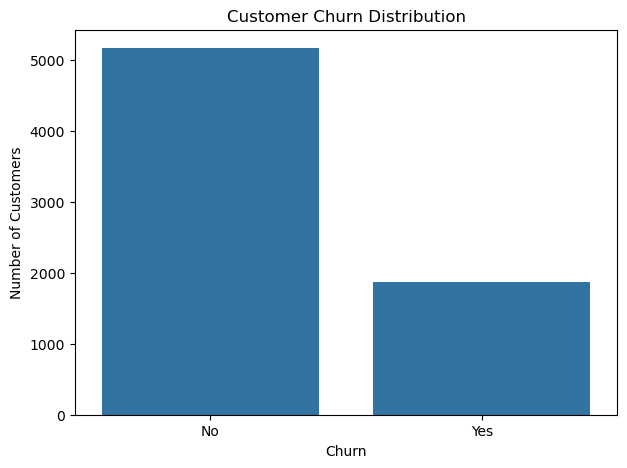

In [15]:
# رسم توزيع العملاء حسب حالة المغادرة
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

### تفسير الرسم البياني

يوضح الرسم أن عدد العملاء الذين استمروا مع الشركة بلغ 5,174 عميلًا بنسبة 73.46%، بينما بلغ عدد العملاء الذين غادروا الشركة 1,869 عميلًا بنسبة 26.54%.

نلاحظ أن نسبة العملاء المغادرين تقارب 27% من إجمالي العملاء، وهي نسبة مهمة تستحق اهتمام الشركة والعمل على تقليلها من خلال تحسين الخدمات وتجربة العملاء.  

### تحليل مغادرة العملاء حسب نوع العقد (Contract)   

سأقارن نسبة مغادرة العملاء بين أنواع العقود المختلفة، لمعرفة ما إذا كانت مدة الالتزام بالعقد ترتبط باحتمالية مغادرة العميل للشركة.

In [16]:
# حساب نسبة المغادرة حسب نوع العقد
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("نسبة المغادرة حسب نوع العقد:")
print(contract_churn.round(2))

نسبة المغادرة حسب نوع العقد:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


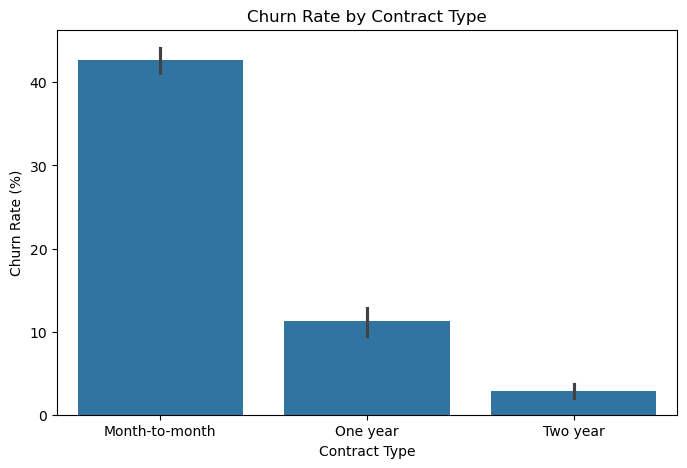

In [17]:
# رسم نسبة المغادرة حسب نوع العقد
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Contract",
    y=df["Churn"].eq("Yes").astype(int) * 100
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

### تفسير الرسم البياني

يوضح الرسم أن نسبة مغادرة العملاء تختلف بشكل واضح حسب نوع العقد.  

بلغت نسبة المغادرة 42.71% للعملاء أصحاب العقود الشهرية، و11.27% لأصحاب عقود السنة الواحدة، بينما انخفضت إلى 2.83% لأصحاب عقود السنتين.

نستنتج أن العملاء أصحاب العقود الشهرية أكثر عرضة لمغادرة الشركة، لذلك نوصي الشركة بتقديم عروض تشجعهم على الانتقال إلى عقود أطول.

### تحليل مدة اشتراك العملاء (Tenure)

سأحلل مدة اشتراك العملاء لمعرفة العلاقة بين طول فترة الاشتراك ومغادرة العميل للشركة، وهل العملاء الجدد أكثر عرضة للمغادرة من العملاء المستمرين منذ فترة طويلة.

In [18]:
# مقارنة متوسط مدة الاشتراك حسب حالة المغادرة
tenure_churn = df.groupby("Churn")["tenure"].mean()

print("متوسط مدة الاشتراك بالأشهر:")
print(tenure_churn.round(2))

متوسط مدة الاشتراك بالأشهر:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64


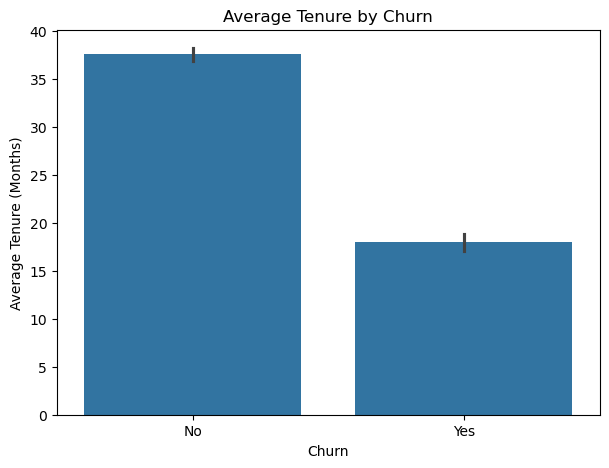

In [19]:
# رسم متوسط مدة الاشتراك حسب حالة المغادرة
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Churn",
    y="tenure",
    estimator="mean"
)

plt.title("Average Tenure by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Tenure (Months)")

plt.show()

### تفسير الرسم البياني

يوضح الرسم أن متوسط مدة اشتراك العملاء المستمرين مع الشركة بلغ 37.57 شهرًا، بينما بلغ متوسط مدة اشتراك العملاء الذين غادروا الشركة 17.98 شهرًا.

نلاحظ أن العملاء الذين يغادرون لديهم مدة اشتراك أقل بكثير من العملاء المستمرين، مما يشير إلى أهمية الاهتمام بالعملاء الجدد خلال الأشهر الأولى من اشتراكهم، وتقديم عروض وخدمات تساعد على الاحتفاظ بهم.  

### تحليل الرسوم الشهرية حسب حالة المغادرة (MonthlyCharges)

سأقارن متوسط الرسوم الشهرية بين العملاء الذين غادروا الشركة والعملاء الذين استمروا معها، لمعرفة ما إذا كانت قيمة الفاتورة الشهرية ترتبط بمغادرة العملاء.  

In [20]:
# مقارنة متوسط الرسوم الشهرية حسب حالة المغادرة
monthly_charges_churn = df.groupby("Churn")["MonthlyCharges"].mean()

print("متوسط الرسوم الشهرية:")
print(monthly_charges_churn.round(2))

متوسط الرسوم الشهرية:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


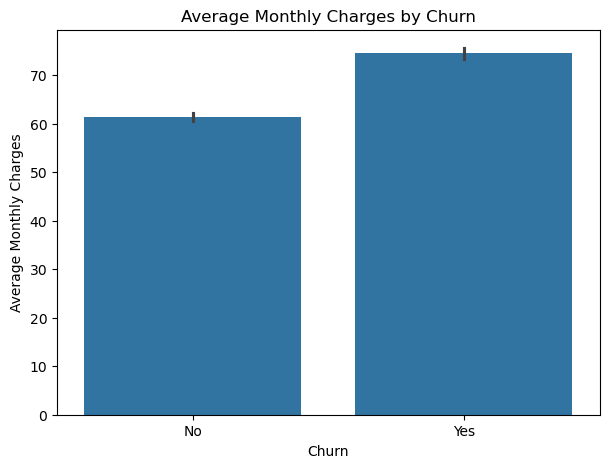

In [21]:
# رسم متوسط الرسوم الشهرية حسب حالة المغادرة
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    estimator="mean"
)

plt.title("Average Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")

plt.show()

### تفسير الرسم البياني

يوضح الرسم أن متوسط الرسوم الشهرية للعملاء الذين استمروا مع الشركة بلغ 61.27، بينما بلغ متوسط الرسوم الشهرية للعملاء الذين غادروا الشركة 74.44.

نلاحظ أن العملاء المغادرين يدفعون رسومًا شهرية أعلى بمتوسط 13.17 تقريبًا مقارنة بالعملاء المستمرين.

تشير هذه النتيجة إلى أهمية مراجعة الأسعار وتقديم باقات مناسبة للعملاء، خصوصًا أصحاب الرسوم الشهرية المرتفعة.

### تحليل مغادرة العملاء حسب خدمة الإنترنت (InternetService)

سأقارن نسبة مغادرة العملاء حسب نوع خدمة الإنترنت المستخدمة، لمعرفة ما إذا كان نوع الخدمة يرتبط بمغادرة العملاء، وتحديد الفئات التي تحتاج إلى اهتمام أكبر من الشركة.  

In [22]:
# حساب نسبة المغادرة حسب نوع خدمة الإنترنت
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("نسبة المغادرة حسب خدمة الإنترنت:")
print(internet_churn.round(2))

نسبة المغادرة حسب خدمة الإنترنت:
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


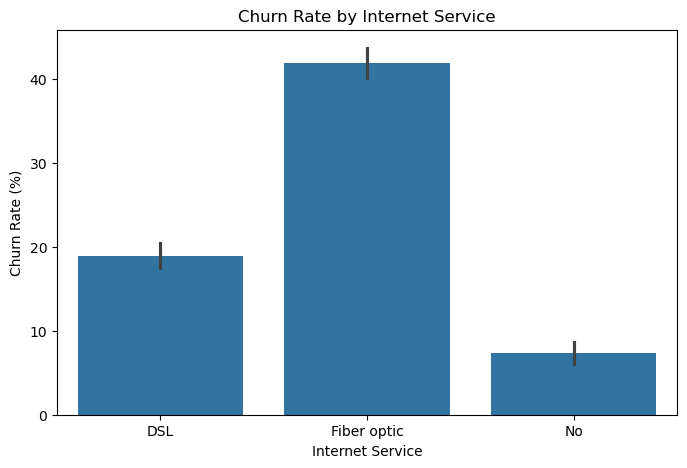

In [23]:
# رسم نسبة مغادرة العملاء حسب خدمة الإنترنت
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="InternetService",
    y=df["Churn"].eq("Yes").astype(int) * 100
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.show()

### تفسير الرسم البياني

يوضح الرسم اختلاف نسبة مغادرة العملاء حسب نوع خدمة الإنترنت.

بلغت نسبة المغادرة لدى عملاء Fiber optic حوالي 41.89%، وهي الأعلى، تليها خدمة DSL بنسبة 18.96%، بينما بلغت النسبة 7.40% لدى العملاء الذين لا يستخدمون خدمة الإنترنت.

تشير النتائج إلى ضرورة مراجعة تجربة عملاء Fiber optic ومعرفة أسباب ارتفاع مغادرتهم، والعمل على تحسين جودة الخدمة ورضا العملاء.

## Task 3: هندسة الخصائص (Feature Engineering)

تهدف هذه المرحلة إلى إنشاء أعمدة جديدة من البيانات الأصلية، تساعد على فهم سلوك العملاء وتحليل العوامل المرتبطة بمغادرتهم للشركة.

سأبدأ بتصنيف مدة اشتراك العملاء إلى مجموعات لتسهيل المقارنة بين العملاء الجدد والعملاء أصحاب الاشتراكات الطويلة.  

In [24]:
# تصنيف العملاء حسب مدة الاشتراك بالأشهر
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

# عرض عدد العملاء في كل مجموعة
print("عدد العملاء حسب مدة الاشتراك:")
print(df["TenureGroup"].value_counts().sort_index())

عدد العملاء حسب مدة الاشتراك:
TenureGroup
0-12 Months     2186
13-24 Months    1024
25-48 Months    1594
49-72 Months    2239
Name: count, dtype: int64


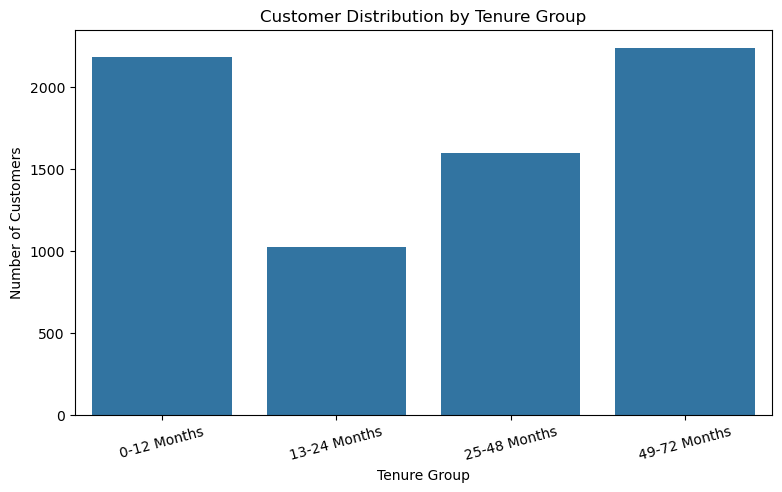

In [25]:
# رسم عدد العملاء حسب مدة الاشتراك
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="TenureGroup",
    order=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

plt.title("Customer Distribution by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

### تفسير الرسم البياني

يوضح الرسم توزيع العملاء حسب مدة الاشتراك.

بلغ عدد العملاء الذين تتراوح مدة اشتراكهم بين 49 و72 شهرًا 2,239 عميلًا، وهي أكبر مجموعة، بينما بلغ عدد العملاء الذين تتراوح مدة اشتراكهم بين 13 و24 شهرًا 1,024 عميلًا، وهي أصغر مجموعة.

يساعدنا هذا التصنيف على مقارنة سلوك العملاء حسب مدة اشتراكهم ومعرفة الفئات التي تحتاج إلى اهتمام أكبر من الشركة.  

### إنشاء خاصية تصنيف الرسوم الشهرية (ChargesGroup)

سأقسم العملاء إلى ثلاث مجموعات حسب قيمة الرسوم الشهرية: منخفضة ومتوسطة ومرتفعة.

يساعدنا هذا التصنيف على معرفة سلوك العملاء حسب مستوى الفاتورة الشهرية، ومقارنة نسب مغادرتهم للشركة.

In [26]:
# تصنيف العملاء حسب الرسوم الشهرية
df["ChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 50, 80, float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

# عرض عدد العملاء في كل مجموعة
print("عدد العملاء حسب الرسوم الشهرية:")
print(df["ChargesGroup"].value_counts().sort_index())

عدد العملاء حسب الرسوم الشهرية:
ChargesGroup
Low       2299
Medium    2078
High      2666
Name: count, dtype: int64


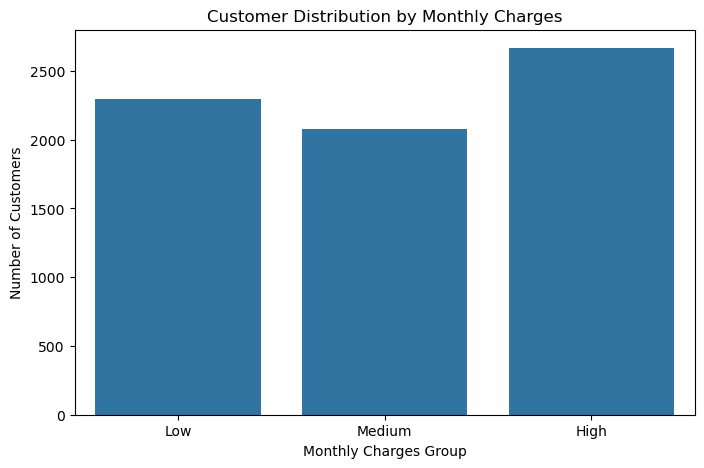

In [27]:
# رسم عدد العملاء حسب الرسوم الشهرية
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="ChargesGroup",
    order=["Low", "Medium", "High"]
)

plt.title("Customer Distribution by Monthly Charges")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Number of Customers")

plt.show()

### تفسير الرسم البياني

يوضح الرسم توزيع العملاء حسب قيمة الرسوم الشهرية.

بلغ عدد العملاء في فئة الرسوم المرتفعة 2,666 عميلًا، وهي أكبر مجموعة، تليها فئة الرسوم المنخفضة بعدد 2,299 عميلًا، ثم فئة الرسوم المتوسطة بعدد 2,078 عميلًا.

يساعدنا هذا التصنيف على دراسة العلاقة بين قيمة الفاتورة الشهرية وسلوك العملاء، ومعرفة ما إذا كانت الفواتير المرتفعة ترتبط بزيادة مغادرة العملاء.  

### تحليل نسبة المغادرة حسب فئة الرسوم الشهرية

سأقارن نسبة مغادرة العملاء بين فئات الرسوم الشهرية الثلاث، لمعرفة ما إذا كانت قيمة الفاتورة الشهرية ترتبط بمغادرة العملاء.

In [28]:
# حساب نسبة المغادرة حسب فئة الرسوم الشهرية
charges_churn = pd.crosstab(
    df["ChargesGroup"],
    df["Churn"],
    normalize="index"
) * 100

print("نسبة المغادرة حسب فئة الرسوم الشهرية:")
print(charges_churn.round(2))

نسبة المغادرة حسب فئة الرسوم الشهرية:
Churn            No    Yes
ChargesGroup              
Low           84.30  15.70
Medium        71.03  28.97
High          66.02  33.98


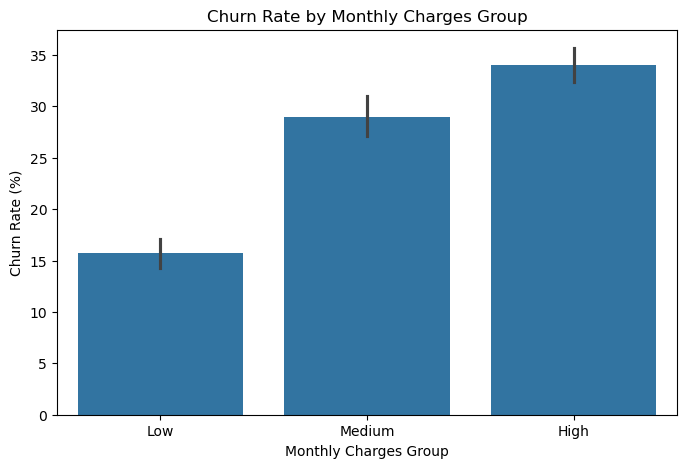

In [29]:
# رسم نسبة المغادرة حسب فئة الرسوم الشهرية
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="ChargesGroup",
    y=df["Churn"].eq("Yes").astype(int) * 100,
    order=["Low", "Medium", "High"]
)

plt.title("Churn Rate by Monthly Charges Group")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Churn Rate (%)")

plt.show()

### تفسير الرسم البياني

يوضح الرسم أن نسبة مغادرة العملاء تختلف حسب فئة الرسوم الشهرية.

بلغت نسبة المغادرة 15.70% في فئة الرسوم المنخفضة، و28.97% في الفئة المتوسطة، بينما وصلت إلى 33.98% في الفئة المرتفعة.

نلاحظ ارتفاع نسبة المغادرة مع ارتفاع الرسوم الشهرية، مما يشير إلى أهمية مراجعة الأسعار وتقديم خيارات وباقات تناسب احتياجات العملاء وميزانياتهم.

## Task 4: اختيار الخصائص (Feature Selection)

في هذه المرحلة سأحدد أهم الخصائص التي ترتبط بمغادرة العملاء، حتى نركز على العوامل الأكثر فائدة في التحليل وتجهيز البيانات للنمذجة مستقبلًا.

سأبدأ بمقارنة نسبة المغادرة بين فئات الخصائص المختلفة، ثم أستخدم النتائج لتحديد أهم العوامل.

### تحليل ارتباط الخصائص الرقمية بمغادرة العملاء

سأحوّل قيمة Churn إلى أرقام، ثم أحسب معامل الارتباط بين الخصائص الرقمية وحالة مغادرة العميل.

يساعدنا ذلك على معرفة الخصائص الرقمية التي تستحق الاهتمام عند تجهيز البيانات للنمذجة.  

In [30]:
# تحويل Churn إلى أرقام
df["Churn_Encoded"] = df["Churn"].map({"No": 0, "Yes": 1})

# اختيار الأعمدة الرقمية
numeric_features = df.select_dtypes(include=["int64", "float64"])

# حساب الارتباط مع Churn
feature_corr = numeric_features.corr()["Churn_Encoded"].drop("Churn_Encoded")

# ترتيب الخصائص حسب قوة الارتباط
feature_corr = feature_corr.sort_values(key=abs, ascending=False)

print("ارتباط الخصائص الرقمية بمغادرة العملاء:")
print(feature_corr.round(3))

ارتباط الخصائص الرقمية بمغادرة العملاء:
tenure           -0.352
TotalCharges     -0.199
MonthlyCharges    0.193
SeniorCitizen     0.151
Name: Churn_Encoded, dtype: float64


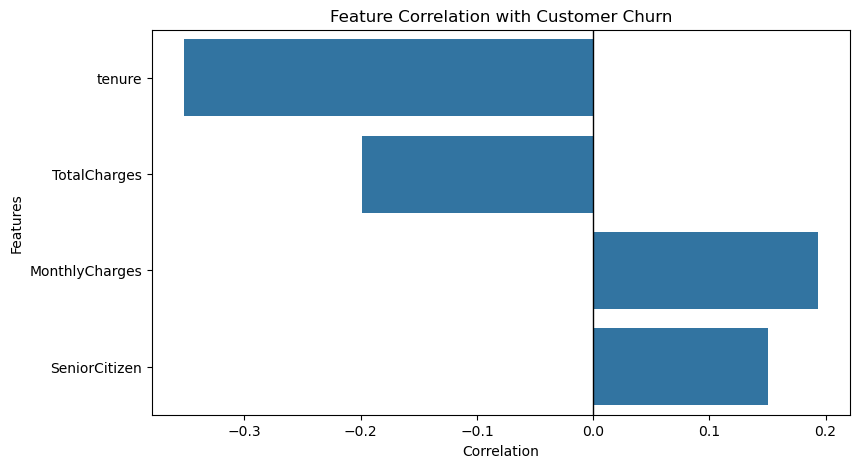

In [31]:
# رسم ارتباط الخصائص الرقمية بمغادرة العملاء
plt.figure(figsize=(9, 5))

sns.barplot(
    x=feature_corr.values,
    y=feature_corr.index
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Feature Correlation with Customer Churn")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.show()

### تفسير الرسم البياني

يوضح الرسم أن مدة الاشتراك (tenure) سجلت أقوى ارتباط بمغادرة العملاء بقيمة -0.352، مما يشير إلى أن زيادة مدة الاشتراك ترتبط بانخفاض احتمالية المغادرة.

كما ظهر ارتباط موجب للرسوم الشهرية بقيمة 0.193، ولإجمالي الرسوم بقيمة -0.199، وللعملاء من كبار السن بقيمة 0.151.

لذلك تعتبر مدة الاشتراك والرسوم الشهرية من الخصائص المهمة التي تستحق التركيز عليها في تحليل مغادرة العملاء.   

### مقارنة الخصائص التصنيفية بمغادرة العملاء

سأقارن نسبة مغادرة العملاء حسب نوع العقد وخدمة الإنترنت ومجموعات مدة الاشتراك والرسوم الشهرية.

يساعدنا ذلك على تحديد الفئات الأكثر ارتباطًا بمغادرة العملاء، واختيار الخصائص المناسبة لتجهيز البيانات.  

In [32]:
# مقارنة نسبة المغادرة حسب الخصائص التصنيفية

categorical_features = [
    "Contract",
    "InternetService",
    "TenureGroup",
    "ChargesGroup"
]

for column in categorical_features:
    churn_rate = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print("\nنسبة المغادرة حسب", column)
    print(churn_rate["Yes"].round(2))


نسبة المغادرة حسب Contract
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Yes, dtype: float64

نسبة المغادرة حسب InternetService
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Yes, dtype: float64

نسبة المغادرة حسب TenureGroup
TenureGroup
0-12 Months     47.44
13-24 Months    28.71
25-48 Months    20.39
49-72 Months     9.51
Name: Yes, dtype: float64

نسبة المغادرة حسب ChargesGroup
ChargesGroup
Low       15.70
Medium    28.97
High      33.98
Name: Yes, dtype: float64


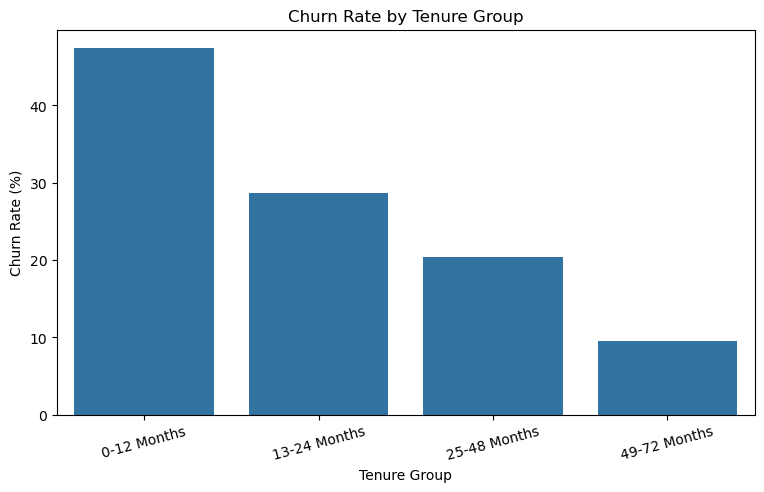

In [33]:
# رسم نسبة المغادرة حسب مدة الاشتراك

tenure_churn_rate = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn_rate.index,
    y=tenure_churn_rate["Yes"]
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.show()

### تفسير الرسم البياني

يوضح الرسم اختلاف نسبة مغادرة العملاء حسب مدة الاشتراك.

بلغت نسبة المغادرة 47.44% لدى العملاء الذين تتراوح مدة اشتراكهم بين 0 و12 شهرًا، وهي أعلى نسبة بين جميع الفئات.

بينما انخفضت النسبة تدريجيًا مع زيادة مدة الاشتراك، حتى وصلت إلى 9.51% لدى العملاء الذين تتراوح مدة اشتراكهم بين 49 و72 شهرًا.

نستنتج أن العملاء الجدد أكثر عرضة للمغادرة، لذلك نوصي الشركة بالاهتمام بالعملاء خلال السنة الأولى من الاشتراك، وتحسين تجربتهم لتشجيعهم على الاستمرار.

### قرار اختيار الخصائص (Feature Selection Decision)

بناءً على نتائج تحليل الارتباط ومقارنة نسب مغادرة العملاء، اخترت الخصائص التالية لأنها تساعد على تفسير سلوك العملاء:

1. `tenure`: لأنها سجلت أقوى ارتباط رقمي بمغادرة العملاء بقيمة -0.352.
2. `Contract`: لأن نسبة المغادرة وصلت إلى 42.71% في العقود الشهرية.
3. `InternetService`: لأن نسبة المغادرة بلغت 41.89% لدى عملاء Fiber optic.
4. `TenureGroup`: لأن نسبة المغادرة وصلت إلى 47.44% لدى العملاء الجدد.
5. `MonthlyCharges`: لوجود ارتباط موجب مع المغادرة بقيمة 0.193.
6. `ChargesGroup`: لأن نسبة المغادرة بلغت 33.98% في فئة الرسوم المرتفعة.
7. `TotalCharges`: لوجود ارتباط مع المغادرة بقيمة -0.199.
8. `SeniorCitizen`: لوجود ارتباط موجب مع المغادرة بقيمة 0.151.

قررت استبعاد `customerID` لأنه مجرد معرّف فريد للعميل ولا يقدم معلومات سلوكية مفيدة للتحليل.

سأحتفظ أيضًا بالعمود `Churn` باعتباره المتغير المستهدف الذي نريد تحليله والتنبؤ به مستقبلًا.

## Task 5: حفظ البيانات النظيفة (Save Clean Data)

بعد الانتهاء من تنظيف البيانات وإنشاء الخصائص الجديدة واختيار الخصائص المهمة، سأحفظ نسخة من البيانات النظيفة لاستخدامها في لوحة المعلومات وتجهيز بيانات النموذج.

In [34]:
# حفظ البيانات النظيفة
df_clean = df.drop(columns=["Churn_Encoded"], errors="ignore")

df_clean.to_csv("telco_clean.csv", index=False)

print("تم حفظ البيانات النظيفة بنجاح")
print("حجم البيانات:", df_clean.shape)
print("عدد القيم الناقصة:", df_clean.isnull().sum().sum())

تم حفظ البيانات النظيفة بنجاح
حجم البيانات: (7043, 23)
عدد القيم الناقصة: 0


## Task 6: تجهيز البيانات للنموذج (Model-Ready Data)

في هذه المرحلة سأختار الخصائص المهمة التي حددتها سابقًا، وأحوّل الأعمدة النصية إلى أعمدة رقمية باستخدام One-Hot Encoding.

سأحوّل Churn إلى 0 و1 ليكون المتغير المستهدف، وأستبعد customerID لأنه مجرد معرّف للعميل.

In [35]:
# اختيار الخصائص المهمة والمتغير المستهدف
selected_features = [
    "tenure",
    "TotalCharges",
    "MonthlyCharges",
    "SeniorCitizen",
    "Contract",
    "InternetService",
    "TenureGroup",
    "ChargesGroup"
]

model_df = df[selected_features + ["Churn"]].copy()

# تحويل المتغير المستهدف إلى أرقام
model_df["Churn"] = model_df["Churn"].map({"No": 0, "Yes": 1})

# تحويل الخصائص النصية إلى أرقام
model_df = pd.get_dummies(
    model_df,
    columns=["Contract", "InternetService", "TenureGroup", "ChargesGroup"],
    drop_first=True,
    dtype=int
)

print("حجم بيانات النموذج:", model_df.shape)
print("\nعدد القيم الناقصة:", model_df.isnull().sum().sum())
print("\nأول خمسة صفوف:")
display(model_df.head())

حجم بيانات النموذج: (7043, 14)

عدد القيم الناقصة: 0

أول خمسة صفوف:


,tenure,TotalCharges,MonthlyCharges,SeniorCitizen,Churn,Contract_One year,Contract_Two year,InternetService_Fiber optic,InternetService_No,TenureGroup_13-24 Months,TenureGroup_25-48 Months,TenureGroup_49-72 Months,ChargesGroup_Medium,ChargesGroup_High
0,1,29.85,29.85,0,0,0,0,0,0,0,0,0,0,0
1,34,1889.50,56.95,0,0,1,0,0,0,0,1,0,1,0
2,2,108.15,53.85,0,1,0,0,0,0,0,0,0,1,0
3,45,1840.75,42.30,0,0,1,0,0,0,0,1,0,0,0
4,2,151.65,70.70,0,1,0,0,1,0,0,0,0,1,0


### حفظ بيانات النموذج

بعد تجهيز الخصائص وتحويل الأعمدة التصنيفية إلى أرقام، سأحفظ البيانات في ملف مستقل لاستخدامه مستقبلًا في بناء نماذج تعلم الآلة.

In [37]:
model_df.to_csv("telco_model_ready.csv", index=False)

print("تم حفظ بيانات النموذج بنجاح")
print("اسم الملف: telco_model_ready.csv")
print("حجم البيانات:", model_df.shape)

تم حفظ بيانات النموذج بنجاح
اسم الملف: telco_model_ready.csv
حجم البيانات: (7043, 14)
